# # Kerala FMCG Sales Analysis, 2025

**Goal:** Analyse sales across brands, districts, channels and months for a simulated Kerala FMCG dataset (5,000 invoices).

**Tools:** Python, pandas, NumPy, Matplotlib

**Key findings:**
- Net sales ₹57.53 lakh; Milma and Double Horse bring in about 30%
- Q4 is the strongest quarter (31.6%); October is the best month
- Distributors generate about 70% of sales; online is only 0.6%
- Ernakulam and Thiruvananthapuram lead; Wayanad is the lowest district

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [52]:
import pandas as pd

df = pd.read_csv("kerala_fmcg_sales_2025.csv")

df.head()

,Invoice_ID,Date,Brand,Product,Category,District,Sales_Channel,Units_Sold,Unit_Price_INR,Gross_Sales_INR,Discount_Percentage,Discount_Amount_INR,Net_Sales_INR,Customer_Type,Payment_Mode
0,KITCH-0001,2025-01-01,Kitchen Treasures,Kitchen Treasures Curry Paste,Curry Paste,Malappuram,Distributor,57,90.0,5130.0,10.0,513.00,4617.00,Distributor,UPI
1,EAST-0001,2025-01-01,Eastern,Eastern Chicken Masala,Masala,Kozhikode,Supermarket,2,39.0,78.0,5.0,3.90,74.10,Retail Customer,Cash
2,NIRA-0001,2025-01-01,Nirapara,Nirapara Rice Powder,Rice,Palakkad,Distributor,20,80.5,1610.0,7.5,120.75,1489.25,Wholesale Customer,UPI
3,KLFN-0001,2025-01-01,KLF Nirmal,KLF Nirmal Coconut Oil,Coconut Oil,Thrissur,Retail Shop,3,247.5,742.5,0.0,0.00,742.50,Retail Customer,UPI
4,ELITE-0001,2025-01-01,Elite Foods,Elite Cake,Cake,Malappuram,Grocery Store,4,92.0,368.0,1.0,3.68,364.32,Retail Customer,Cash


In [53]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset size: (5000, 15)

Column names:
['Invoice_ID', 'Date', 'Brand', 'Product', 'Category', 'District', 'Sales_Channel', 'Units_Sold', 'Unit_Price_INR', 'Gross_Sales_INR', 'Discount_Percentage', 'Discount_Amount_INR', 'Net_Sales_INR', 'Customer_Type', 'Payment_Mode']

Missing values:
Invoice_ID             0
Date                   0
Brand                  0
Product                0
Category               0
District               0
Sales_Channel          0
Units_Sold             0
Unit_Price_INR         0
Gross_Sales_INR        0
Discount_Percentage    0
Discount_Amount_INR    0
Net_Sales_INR          0
Customer_Type          0
Payment_Mode           0
dtype: int64


In [54]:
import pandas as pd

df = pd.read_csv("kerala_fmcg_sales_2025.csv")

print(df.head())

   Invoice_ID        Date              Brand                        Product  \
0  KITCH-0001  2025-01-01  Kitchen Treasures  Kitchen Treasures Curry Paste   
1   EAST-0001  2025-01-01            Eastern         Eastern Chicken Masala   
2   NIRA-0001  2025-01-01           Nirapara           Nirapara Rice Powder   
3   KLFN-0001  2025-01-01         KLF Nirmal         KLF Nirmal Coconut Oil   
4  ELITE-0001  2025-01-01        Elite Foods                     Elite Cake   

      Category    District  Sales_Channel  Units_Sold  Unit_Price_INR  \
0  Curry Paste  Malappuram    Distributor          57            90.0   
1       Masala   Kozhikode    Supermarket           2            39.0   
2         Rice    Palakkad    Distributor          20            80.5   
3  Coconut Oil    Thrissur    Retail Shop           3           247.5   
4         Cake  Malappuram  Grocery Store           4            92.0   

   Gross_Sales_INR  Discount_Percentage  Discount_Amount_INR  Net_Sales_INR  \
0      

In [55]:
# Quick profile
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate invoice IDs:")
print(df["Invoice_ID"].duplicated().sum())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (5000, 15)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Invoice_ID           5000 non-null   str    
 1   Date                 5000 non-null   str    
 2   Brand                5000 non-null   str    
 3   Product              5000 non-null   str    
 4   Category             5000 non-null   str    
 5   District             5000 non-null   str    
 6   Sales_Channel        5000 non-null   str    
 7   Units_Sold           5000 non-null   int64  
 8   Unit_Price_INR       5000 non-null   float64
 9   Gross_Sales_INR      5000 non-null   float64
 10  Discount_Percentage  5000 non-null   float64
 11  Discount_Amount_INR  5000 non-null   float64
 12  Net_Sales_INR        5000 non-null   float64
 13  Customer_Type        5000 non-null   str    
 14  Payment_Mode         5000 non-null   str    
dtypes:

In [56]:

# Step 1: Make a copy so the original data remains unchanged
df_clean = df.copy()

# Step 2: Remove unnecessary spaces from text columns
text_cols = [
    "Invoice_ID", "Brand", "Product", "Category",
    "District", "Sales_Channel", "Customer_Type",
    "Payment_Mode"
]

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

# Step 3: Convert Date to a proper date format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"], errors="coerce", dayfirst=True
)

print("Invalid dates:", df_clean["Date"].isna().sum())

# Step 4: Validate gross sales
gross_check = (
    df_clean["Units_Sold"] * df_clean["Unit_Price_INR"]
    - df_clean["Gross_Sales_INR"]
).abs()

print("Gross sales mismatches:", (gross_check >= 0.01).sum())

# Step 5: Validate discount amount
expected_discount = (
    df_clean["Gross_Sales_INR"]
    * df_clean["Discount_Percentage"] / 100
)

discount_check = (
    expected_discount - df_clean["Discount_Amount_INR"]
).abs()

print("Discount mismatches:", (discount_check >= 0.01).sum())

# Step 6: Validate net sales
net_check = (
    df_clean["Gross_Sales_INR"]
    - df_clean["Discount_Amount_INR"]
    - df_clean["Net_Sales_INR"]
).abs()

print("Net sales mismatches:", (net_check >= 0.01).sum())


Invalid dates: 2984
Gross sales mismatches: 0
Discount mismatches: 0
Net sales mismatches: 0


In [57]:
print(
    df.loc[
        df_clean["Date"].isna(),
        "Date"
    ].head(20).to_list()
)

['2025-01-13', '2025-01-13', '2025-01-13', '2025-01-13', '2025-01-13', '2025-01-13', '2025-01-13', '2025-01-14', '2025-01-14', '2025-01-14', '2025-01-14', '2025-01-14', '2025-01-15', '2025-01-15', '2025-01-15', '2025-01-15', '2025-01-15', '2025-01-15', '2025-01-15', '2025-01-15']


In [58]:
print(df["Date"].astype(str).str.extract(
    r"^(\d{1,4})[-/](\d{1,2})[-/](\d{1,4})$"
).value_counts().head(15))

0     1   2 
2025  08  31    31
      09  01    29
          03    29
      10  17    29
      09  02    28
      10  24    28
      12  13    27
          08    26
          23    26
      11  24    25
      12  14    25
      07  04    24
      09  27    24
      12  21    24
      08  26    23
Name: count, dtype: int64


In [59]:
# Convert dates using the correct year-month-day format
df_clean["Date"] = pd.to_datetime(
    df["Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

print("Invalid dates:", df_clean["Date"].isna().sum())
print(df_clean["Date"].head())

Invalid dates: 0
0   2025-01-01
1   2025-01-01
2   2025-01-01
3   2025-01-01
4   2025-01-01
Name: Date, dtype: datetime64[us]


In [60]:
df_clean["Year"] = df_clean["Date"].dt.year
df_clean["Month_Num"] = df_clean["Date"].dt.month
df_clean["Month_Name"] = df_clean["Date"].dt.strftime("%b")
df_clean["Quarter"] = "Q" + df_clean["Date"].dt.quarter.astype(str)
df_clean["Weekday"] = df_clean["Date"].dt.day_name()

df_clean[["Date", "Year", "Month_Num", "Month_Name",
          "Quarter", "Weekday"]].head()

,Date,Year,Month_Num,Month_Name,Quarter,Weekday
0,2025-01-01,2025,1,Jan,Q1,Wednesday
1,2025-01-01,2025,1,Jan,Q1,Wednesday
2,2025-01-01,2025,1,Jan,Q1,Wednesday
3,2025-01-01,2025,1,Jan,Q1,Wednesday
4,2025-01-01,2025,1,Jan,Q1,Wednesday


In [61]:
print("Unique original dates:", df["Date"].nunique())
print("Unique converted dates:", df_clean["Date"].nunique())
print("Earliest date:", df_clean["Date"].min())
print("Latest date:", df_clean["Date"].max())

Unique original dates: 365
Unique converted dates: 365
Earliest date: 2025-01-01 00:00:00
Latest date: 2025-12-31 00:00:00


In [62]:
print(df_clean[[
    "Date", "Year", "Month_Num",
    "Month_Name", "Quarter", "Weekday"
]].head(10).to_string(index=False))

      Date  Year  Month_Num Month_Name Quarter   Weekday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday
2025-01-01  2025          1        Jan      Q1 Wednesday


In [63]:
print("First 10 distinct dates:")
print(sorted(df_clean["Date"].dropna().unique())[:10])

print("\nLast 10 distinct dates:")
print(sorted(df_clean["Date"].dropna().unique())[-10:])

print("\nInvoices per date:")
print(df_clean["Date"].value_counts().describe())

First 10 distinct dates:
[Timestamp('2025-01-01 00:00:00'), Timestamp('2025-01-02 00:00:00'), Timestamp('2025-01-03 00:00:00'), Timestamp('2025-01-04 00:00:00'), Timestamp('2025-01-05 00:00:00'), Timestamp('2025-01-06 00:00:00'), Timestamp('2025-01-07 00:00:00'), Timestamp('2025-01-08 00:00:00'), Timestamp('2025-01-09 00:00:00'), Timestamp('2025-01-10 00:00:00')]

Last 10 distinct dates:
[Timestamp('2025-12-22 00:00:00'), Timestamp('2025-12-23 00:00:00'), Timestamp('2025-12-24 00:00:00'), Timestamp('2025-12-25 00:00:00'), Timestamp('2025-12-26 00:00:00'), Timestamp('2025-12-27 00:00:00'), Timestamp('2025-12-28 00:00:00'), Timestamp('2025-12-29 00:00:00'), Timestamp('2025-12-30 00:00:00'), Timestamp('2025-12-31 00:00:00')]

Invoices per date:
count    365.000000
mean      13.698630
std        4.989783
min        1.000000
25%       10.000000
50%       13.000000
75%       17.000000
max       31.000000
Name: count, dtype: float64


In [64]:
df_clean.to_csv(
    "kerala_fmcg_clean.csv",
    index=False
)

print("Export completed!")
print("Dataset shape:", df_clean.shape)

Export completed!
Dataset shape: (5000, 20)


In [65]:
print("Total Units Sold:", df_clean["Units_Sold"].sum())

print("Total Gross Sales (₹):",
      round(df_clean["Gross_Sales_INR"].sum(), 2))

print("Total Discounts (₹):",
      round(df_clean["Discount_Amount_INR"].sum(), 2))

print("Total Net Sales (₹):",
      round(df_clean["Net_Sales_INR"].sum(), 2))

print("Average Invoice Value (₹):",
      round(df_clean["Net_Sales_INR"].mean(), 2))

Total Units Sold: 60226
Total Gross Sales (₹): 6426972.0
Total Discounts (₹): 674380.27
Total Net Sales (₹): 5752591.73
Average Invoice Value (₹): 1150.52


In [66]:

# Top 5 brands by net sales
brand_sales = (
    df_clean.groupby("Brand")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
    .sort_values("Total_Net_Sales", ascending=False)
)

print(brand_sales.head(5).round(2))



              Total_Net_Sales  Units_Sold  Invoice_Count
Brand                                                   
Milma               881001.44       11763            750
Double Horse        842468.07        6031            500
Nirapara            695969.07        5325            450
Eastern             559761.04        6410            600
KLF Nirmal          539810.25        2622            250


In [67]:
brand_sales = (
    df_clean.groupby("Brand")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
    .sort_values("Total_Net_Sales", ascending=False)
)

print(brand_sales.round(2))

                   Total_Net_Sales  Units_Sold  Invoice_Count
Brand                                                        
Milma                    881001.44       11763            750
Double Horse             842468.07        6031            500
Nirapara                 695969.07        5325            450
Eastern                  559761.04        6410            600
KLF Nirmal               539810.25        2622            250
Pavizham                 504842.58        4235            350
Brahmins                 388299.93        4453            400
Elite Foods              282522.74        5506            400
Elanadu                  259027.94        2904            250
Kitchen Treasures        224794.41        2877            300
Melam                    208520.76        3029            250
AJMI Foods               204827.48        2981            250
Devon Foods              160746.02        2090            250


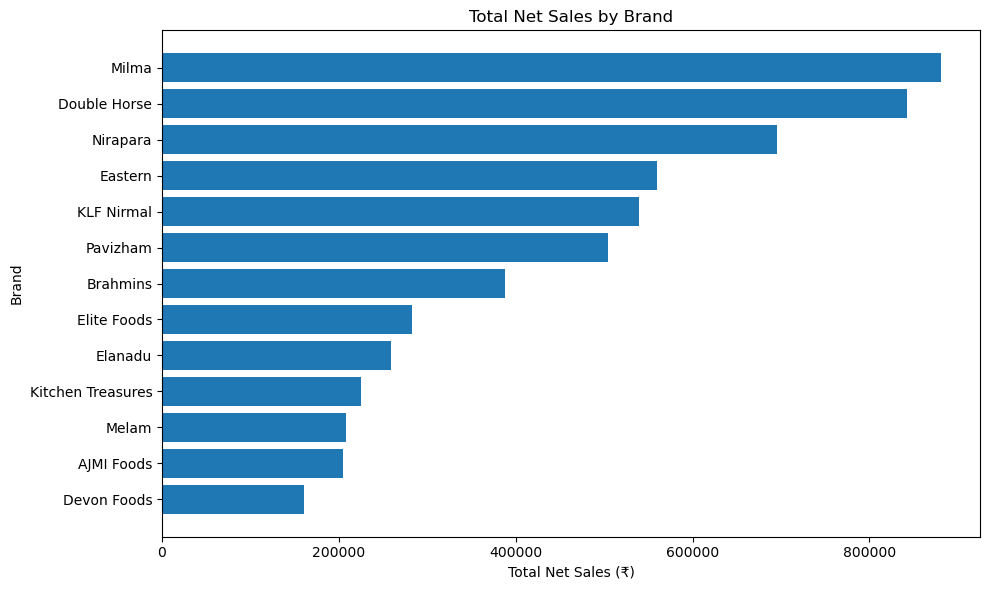

In [68]:
import matplotlib.pyplot as plt

brand_sales_plot = brand_sales.sort_values(
    "Total_Net_Sales", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    brand_sales_plot.index,
    brand_sales_plot["Total_Net_Sales"]
)

plt.title("Total Net Sales by Brand")
plt.xlabel("Total Net Sales (₹)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

In [69]:
district_sales = (
    df_clean.groupby("District")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
    .sort_values("Total_Net_Sales", ascending=False)
)

print(district_sales.round(2))

                    Total_Net_Sales  Units_Sold  Invoice_Count
District                                                      
Ernakulam                 779694.58        8201            692
Thiruvananthapuram        740824.62        7631            586
Malappuram                618195.91        6016            484
Kozhikode                 539603.39        6933            473
Thrissur                  515628.28        5413            491
Kollam                    451504.02        4280            342
Kottayam                  413879.25        4016            347
Palakkad                  345313.19        3647            340
Alappuzha                 343724.50        3924            292
Kannur                    331664.53        3329            284
Pathanamthitta            225104.17        2327            185
Kasaragod                 196628.68        2241            217
Idukki                    163750.53        1281            149
Wayanad                    87076.08         987        

In [70]:
monthly_sales = (
    df_clean.groupby(["Month_Num", "Month_Name"])
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
    .reset_index()
    .sort_values("Month_Num")
)

print(monthly_sales.round(2))

    Month_Num Month_Name  Total_Net_Sales  Units_Sold  Invoice_Count
0           1        Jan        449945.87        4563            300
1           2        Feb        348913.03        3569            300
2           3        Mar        361022.78        3998            350
3           4        Apr        320542.38        3790            350
4           5        May        364962.28        3944            350
5           6        Jun        386267.10        4332            400
6           7        Jul        557236.95        4587            400
7           8        Aug        462544.18        5312            450
8           9        Sep        683985.64        6443            550
9          10        Oct        700736.54        7272            500
10         11        Nov        522103.44        5772            500
11         12        Dec        594331.54        6644            550


In [71]:

brand_analysis = (
    df_clean.groupby("Brand")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Total_Gross_Sales=("Gross_Sales_INR", "sum"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
)

# Percentage of total net sales contributed by each brand
brand_analysis["Sales_Share_%"] = (
    brand_analysis["Total_Net_Sales"]
    / df_clean["Net_Sales_INR"].sum()
    * 100
)

# Discount as a percentage of gross sales for each brand
brand_analysis["Discount_%"] = (
    brand_analysis["Total_Discount"]
    / brand_analysis["Total_Gross_Sales"]
    * 100
)

# Sort brands from highest to lowest net sales
brand_analysis = brand_analysis.sort_values(
    "Total_Net_Sales",
    ascending=False
)

print(brand_analysis.round(2))


                   Total_Net_Sales  Total_Gross_Sales  Total_Discount  \
Brand                                                                   
Milma                    881001.44           984898.5       103897.06   
Double Horse             842468.07           939162.5        96694.43   
Nirapara                 695969.07           773894.0        77924.93   
Eastern                  559761.04           629650.5        69889.46   
KLF Nirmal               539810.25           597219.0        57408.75   
Pavizham                 504842.58           563830.5        58987.92   
Brahmins                 388299.93           434334.0        46034.07   
Elite Foods              282522.74           320424.0        37901.26   
Elanadu                  259027.94           293089.0        34061.06   
Kitchen Treasures        224794.41           251221.0        26426.59   
Melam                    208520.76           232762.5        24241.74   
AJMI Foods               204827.48           227015

In [72]:

print("Top brand by net sales:")
print(brand_analysis.iloc[0])

print("\nLowest brand by net sales:")
print(brand_analysis.iloc[-1])

print("\nTotal sales share across brands:")
print(round(brand_analysis["Sales_Share_%"].sum(), 2), "%")


Top brand by net sales:
Total_Net_Sales      881001.440000
Total_Gross_Sales    984898.500000
Total_Discount       103897.060000
Units_Sold            11763.000000
Invoice_Count           750.000000
Sales_Share_%            15.314861
Discount_%               10.549012
Name: Milma, dtype: float64

Lowest brand by net sales:
Total_Net_Sales      160746.020000
Total_Gross_Sales    179471.000000
Total_Discount        18724.980000
Units_Sold             2090.000000
Invoice_Count           250.000000
Sales_Share_%             2.794323
Discount_%               10.433429
Name: Devon Foods, dtype: float64

Total sales share across brands:
100.0 %


In [73]:

district_analysis = (
    df_clean.groupby("District")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Total_Gross_Sales=("Gross_Sales_INR", "sum"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
)

# Share of total net sales
district_analysis["Sales_Share_%"] = (
    district_analysis["Total_Net_Sales"]
    / df_clean["Net_Sales_INR"].sum()
    * 100
)

# Weighted discount percentage
district_analysis["Discount_%"] = (
    district_analysis["Total_Discount"]
    / district_analysis["Total_Gross_Sales"]
    * 100
)

# Rank districts by net sales
district_analysis = district_analysis.sort_values(
    "Total_Net_Sales",
    ascending=False
)

print(district_analysis.round(2))


                    Total_Net_Sales  Total_Gross_Sales  Total_Discount  \
District                                                                 
Ernakulam                 779694.58           870696.5        91001.92   
Thiruvananthapuram        740824.62           832700.5        91875.88   
Malappuram                618195.91           690576.5        72380.59   
Kozhikode                 539603.39           603051.5        63448.11   
Thrissur                  515628.28           577004.5        61376.22   
Kollam                    451504.02           512579.0        61074.98   
Kottayam                  413879.25           458888.0        45008.75   
Palakkad                  345313.19           381238.0        35924.81   
Alappuzha                 343724.50           381457.0        37732.50   
Kannur                    331664.53           366921.0        35256.47   
Pathanamthitta            225104.17           254943.5        29839.33   
Kasaragod                 196628.68   

In [74]:

print("Top district:")
print(district_analysis.iloc[0])

print("\nLowest district:")
print(district_analysis.iloc[-1])

print("\nTotal district sales share:")
print(round(district_analysis["Sales_Share_%"].sum(), 2), "%")

print("\nNumber of districts:", df_clean["District"].nunique())


Top district:
Total_Net_Sales      779694.580000
Total_Gross_Sales    870696.500000
Total_Discount        91001.920000
Units_Sold             8201.000000
Invoice_Count           692.000000
Sales_Share_%            13.553797
Discount_%               10.451623
Name: Ernakulam, dtype: float64

Lowest district:
Total_Net_Sales      87076.080000
Total_Gross_Sales    98786.500000
Total_Discount       11710.420000
Units_Sold             987.000000
Invoice_Count          118.000000
Sales_Share_%            1.513684
Discount_%              11.854272
Name: Wayanad, dtype: float64

Total district sales share:
100.0 %

Number of districts: 14


In [75]:

monthly_analysis = (
    df_clean.groupby(["Month_Num", "Month_Name"])
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Total_Gross_Sales=("Gross_Sales_INR", "sum"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
    .reset_index()
    .sort_values("Month_Num")
)

monthly_analysis["MoM_Growth_%"] = (
    monthly_analysis["Total_Net_Sales"].pct_change() * 100
)

print(monthly_analysis.round(2))


    Month_Num Month_Name  Total_Net_Sales  Total_Gross_Sales  Total_Discount  \
0           1        Jan        449945.87           505147.5        55201.63   
1           2        Feb        348913.03           388966.5        40053.47   
2           3        Mar        361022.78           401643.5        40620.72   
3           4        Apr        320542.38           356815.0        36272.62   
4           5        May        364962.28           408191.0        43228.72   
5           6        Jun        386267.10           427659.5        41392.40   
6           7        Jul        557236.95           616485.5        59248.55   
7           8        Aug        462544.18           520923.5        58379.32   
8           9        Sep        683985.64           761769.5        77783.86   
9          10        Oct        700736.54           785320.0        84583.46   
10         11        Nov        522103.44           581323.0        59219.56   
11         12        Dec        594331.5

In [76]:

best_month = monthly_analysis.loc[
    monthly_analysis["Total_Net_Sales"].idxmax()
]

worst_month = monthly_analysis.loc[
    monthly_analysis["Total_Net_Sales"].idxmin()
]

print("Best month:", best_month["Month_Name"])
print("Highest net sales: ₹", round(best_month["Total_Net_Sales"], 2))

print("\nWorst month:", worst_month["Month_Name"])
print("Lowest net sales: ₹", round(worst_month["Total_Net_Sales"], 2))


Best month: Oct
Highest net sales: ₹ 700736.54

Worst month: Apr
Lowest net sales: ₹ 320542.38


In [77]:

quarterly_analysis = (
    df_clean.groupby("Quarter")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Total_Gross_Sales=("Gross_Sales_INR", "sum"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
)

quarterly_analysis["Sales_Share_%"] = (
    quarterly_analysis["Total_Net_Sales"]
    / df_clean["Net_Sales_INR"].sum()
    * 100
)

quarterly_analysis["Discount_%"] = (
    quarterly_analysis["Total_Discount"]
    / quarterly_analysis["Total_Gross_Sales"]
    * 100
)

# Ensure quarters appear in calendar order
quarterly_analysis = quarterly_analysis.reindex(
    ["Q1", "Q2", "Q3", "Q4"]
)

print(quarterly_analysis.round(2))


         Total_Net_Sales  Total_Gross_Sales  Total_Discount  Units_Sold  \
Quarter                                                                   
Q1            1159881.68          1295757.5       135875.82       12130   
Q2            1071771.76          1192665.5       120893.74       12066   
Q3            1703766.77          1899178.5       195411.73       16342   
Q4            1817171.52          2039370.5       222198.98       19688   

         Invoice_Count  Sales_Share_%  Discount_%  
Quarter                                            
Q1                 950          20.16       10.49  
Q2                1100          18.63       10.14  
Q3                1400          29.62       10.29  
Q4                1550          31.59       10.90  


In [78]:

print(
    "Best quarter:",
    quarterly_analysis["Total_Net_Sales"].idxmax()
)

print(
    "Worst quarter:",
    quarterly_analysis["Total_Net_Sales"].idxmin()
)


Best quarter: Q4
Worst quarter: Q2


In [79]:

category_analysis = (
    df_clean.groupby("Category")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Total_Gross_Sales=("Gross_Sales_INR", "sum")
    )
)

category_analysis["Sales_Share_%"] = (
    category_analysis["Total_Net_Sales"]
    / df_clean["Net_Sales_INR"].sum() * 100
)

category_analysis["Discount_%"] = (
    category_analysis["Total_Discount"]
    / category_analysis["Total_Gross_Sales"] * 100
)

category_analysis = category_analysis.sort_values(
    "Total_Net_Sales", ascending=False
)

print(category_analysis.round(2))


                    Total_Net_Sales  Units_Sold  Invoice_Count  \
Category                                                         
Rice                     1200833.39        4395            422   
Spice Powder              482777.13        4780            440   
Breakfast Mix             469837.07        6434            569   
Ghee                      399262.32        1228            128   
Coconut Oil               383777.51        1676            150   
Masala                    340200.02        5206            556   
Spices                    329257.75        4325            312   
Rice Products             267424.06        4364            392   
Milk                      236562.67        6391            389   
Pickles                   177611.12        2005            142   
Butter                    173029.66        1043             95   
Curd                      139959.10        2983            168   
Curry Powder              119692.27        1442            148   
Edible Oil

In [80]:

product_analysis = (
    df_clean.groupby("Product")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
    .sort_values("Total_Net_Sales", ascending=False)
)

print(product_analysis.head(10).round(2))


                             Total_Net_Sales  Units_Sold  Invoice_Count
Product                                                                
Double Horse Matta Rice            496881.82        1434            113
Nirapara Matta Rice                401003.12        1147            115
Milma Ghee                         284304.97         976             90
KLF Nirmal Coconut Oil             277129.89        1113            104
Pavizham Matta Rice                242736.18         722             94
Eastern Chilli Powder              222834.06        1815            131
Milma Butter                       167584.43        1007             85
Double Horse Idiyappam Podi        127815.85        1724             80
Milma Milk                         123519.75        3333            171
Elanadu Ghee                       114957.35         252             38


In [81]:

channel_analysis = (
    df_clean.groupby("Sales_Channel")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Total_Gross_Sales=("Gross_Sales_INR", "sum"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
)

channel_analysis["Average_Invoice_Value"] = (
    channel_analysis["Total_Net_Sales"]
    / channel_analysis["Invoice_Count"]
)

channel_analysis["Discount_%"] = (
    channel_analysis["Total_Discount"]
    / channel_analysis["Total_Gross_Sales"]
    * 100
)

channel_analysis = channel_analysis.sort_values(
    "Total_Net_Sales",
    ascending=False
)

print(channel_analysis.round(2))


               Total_Net_Sales  Total_Gross_Sales  Total_Discount  Units_Sold  \
Sales_Channel                                                                   
Distributor         4049371.04          4567468.5       518097.46       40747   
Grocery Store        851901.09           927842.0        75940.91        9220   
Supermarket          402844.54           442254.5        39409.96        5087   
Retail Shop          316909.44           345889.5        28980.06        3443   
Hypermarket           99450.61           109218.5         9767.89        1292   
Online                32115.01            34299.0         2183.99         437   

               Invoice_Count  Average_Invoice_Value  Discount_%  
Sales_Channel                                                    
Distributor              729                5554.69       11.34  
Grocery Store           1775                 479.94        8.18  
Supermarket             1260                 319.72        8.91  
Retail Shop          

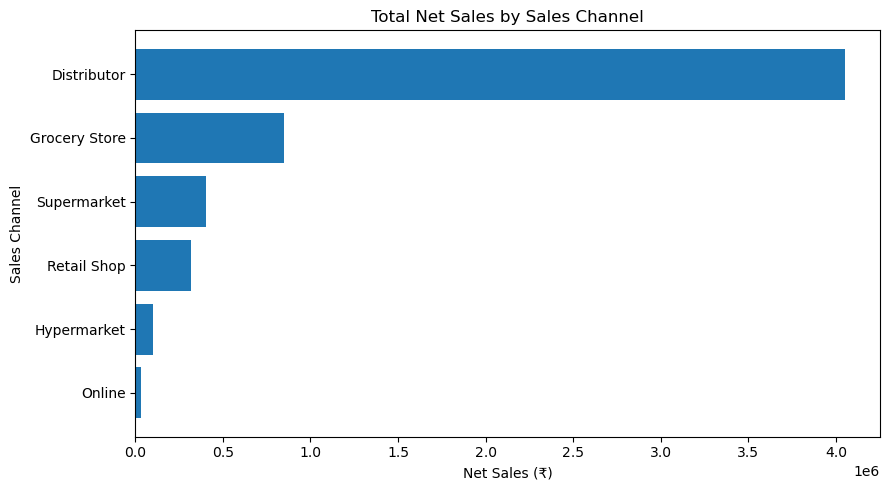

In [82]:

channel_plot = channel_analysis.sort_values(
    "Total_Net_Sales",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    channel_plot.index,
    channel_plot["Total_Net_Sales"]
)

plt.title("Total Net Sales by Sales Channel")
plt.xlabel("Net Sales (₹)")
plt.ylabel("Sales Channel")

plt.tight_layout()
plt.show()


In [83]:

customer_analysis = (
    df_clean.groupby("Customer_Type")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Total_Gross_Sales=("Gross_Sales_INR", "sum")
    )
)

customer_analysis["Sales_Share_%"] = (
    customer_analysis["Total_Net_Sales"]
    / df_clean["Net_Sales_INR"].sum() * 100
)

customer_analysis["Average_Invoice_Value"] = (
    customer_analysis["Total_Net_Sales"]
    / customer_analysis["Invoice_Count"]
)

customer_analysis["Discount_%"] = (
    customer_analysis["Total_Discount"]
    / customer_analysis["Total_Gross_Sales"] * 100
)

print(customer_analysis.round(2))


                    Total_Net_Sales  Units_Sold  Invoice_Count  \
Customer_Type                                                    
Distributor              3287295.20       33171            462   
Retail Customer           926712.97       12280           3984   
Wholesale Customer       1538583.56       14775            554   

                    Total_Discount  Total_Gross_Sales  Sales_Share_%  \
Customer_Type                                                          
Distributor              419953.30          3707248.5          57.14   
Retail Customer           52708.03           979421.0          16.11   
Wholesale Customer       201718.94          1740302.5          26.75   

                    Average_Invoice_Value  Discount_%  
Customer_Type                                          
Distributor                       7115.36       11.33  
Retail Customer                    232.61        5.38  
Wholesale Customer                2777.23       11.59  


In [84]:

payment_analysis = (
    df_clean.groupby("Payment_Mode")
    .agg(
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Invoice_Count=("Invoice_ID", "nunique")
    )
    .sort_values("Total_Net_Sales", ascending=False)
)

payment_analysis["Sales_Share_%"] = (
    payment_analysis["Total_Net_Sales"]
    / df_clean["Net_Sales_INR"].sum() * 100
)

payment_analysis["Average_Invoice_Value"] = (
    payment_analysis["Total_Net_Sales"]
    / payment_analysis["Invoice_Count"]
)

print(payment_analysis.round(2))


               Total_Net_Sales  Units_Sold  Invoice_Count  Sales_Share_%  \
Payment_Mode                                                               
Bank Transfer       2427714.30       25419            503          42.20   
UPI                 1994342.20       20512           2209          34.67   
Cash                 728133.64        7419           1259          12.66   
Credit Card          335020.89        3409            438           5.82   
Debit Card           267380.70        3467            591           4.65   

               Average_Invoice_Value  
Payment_Mode                          
Bank Transfer                4826.47  
UPI                           902.83  
Cash                          578.34  
Credit Card                   764.89  
Debit Card                    452.42  


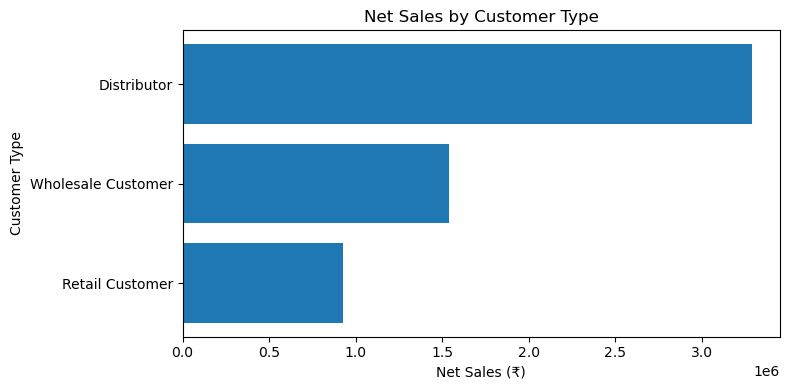

In [85]:

customer_plot = customer_analysis.sort_values(
    "Total_Net_Sales", ascending=True
)

plt.figure(figsize=(8, 4))

plt.barh(
    customer_plot.index,
    customer_plot["Total_Net_Sales"]
)

plt.title("Net Sales by Customer Type")
plt.xlabel("Net Sales (₹)")
plt.ylabel("Customer Type")

plt.tight_layout()
plt.show()


In [86]:

discount_by_brand = (
    df_clean.groupby("Brand")
    .agg(
        Total_Gross_Sales=("Gross_Sales_INR", "sum"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum"),
        Avg_Discount_Rate=("Discount_Percentage", "mean")
    )
)

discount_by_brand["Weighted_Discount_%"] = (
    discount_by_brand["Total_Discount"]
    / discount_by_brand["Total_Gross_Sales"]
    * 100
)

discount_by_brand = discount_by_brand.sort_values(
    "Weighted_Discount_%", ascending=False
)

print(discount_by_brand.round(2))


                   Total_Gross_Sales  Total_Discount  Total_Net_Sales  \
Brand                                                                   
Elite Foods                 320424.0        37901.26        282522.74   
Elanadu                     293089.0        34061.06        259027.94   
Eastern                     629650.5        69889.46        559761.04   
Brahmins                    434334.0        46034.07        388299.93   
Milma                       984898.5       103897.06        881001.44   
Kitchen Treasures           251221.0        26426.59        224794.41   
Pavizham                    563830.5        58987.92        504842.58   
Devon Foods                 179471.0        18724.98        160746.02   
Melam                       232762.5        24241.74        208520.76   
Double Horse                939162.5        96694.43        842468.07   
Nirapara                    773894.0        77924.93        695969.07   
AJMI Foods                  227015.5        22188.0

In [87]:

discount_by_channel = (
    df_clean.groupby("Sales_Channel")
    .agg(
        Total_Gross_Sales=("Gross_Sales_INR", "sum"),
        Total_Discount=("Discount_Amount_INR", "sum"),
        Total_Net_Sales=("Net_Sales_INR", "sum"),
        Units_Sold=("Units_Sold", "sum")
    )
)

discount_by_channel["Weighted_Discount_%"] = (
    discount_by_channel["Total_Discount"]
    / discount_by_channel["Total_Gross_Sales"]
    * 100
)

print(discount_by_channel.sort_values(
    "Weighted_Discount_%", ascending=False
).round(2))


               Total_Gross_Sales  Total_Discount  Total_Net_Sales  Units_Sold  \
Sales_Channel                                                                   
Distributor            4567468.5       518097.46       4049371.04       40747   
Hypermarket             109218.5         9767.89         99450.61        1292   
Supermarket             442254.5        39409.96        402844.54        5087   
Retail Shop             345889.5        28980.06        316909.44        3443   
Grocery Store           927842.0        75940.91        851901.09        9220   
Online                   34299.0         2183.99         32115.01         437   

               Weighted_Discount_%  
Sales_Channel                       
Distributor                  11.34  
Hypermarket                   8.94  
Supermarket                   8.91  
Retail Shop                   8.38  
Grocery Store                 8.18  
Online                        6.37  


In [89]:

brand_district = pd.pivot_table(
    df_clean,
    index="Brand",
    columns="District",
    values="Net_Sales_INR",
    aggfunc="sum",
    fill_value=0
)

print(brand_district.round(2))


District           Alappuzha  Ernakulam    Idukki     Kannur  Kasaragod  \
Brand                                                                     
AJMI Foods          35109.16   26380.01  18221.86    1042.14    6107.83   
Brahmins             9004.60   45917.80  19126.63   34105.78    8639.45   
Devon Foods         13312.00   14866.16   7839.45   10144.09   22662.39   
Double Horse         8835.36  111188.42  26307.25   66020.57   56877.00   
Eastern             19848.23   65593.34   7429.19  101851.04    7283.66   
Elanadu             18465.40   31275.43    836.35   30240.62   11200.40   
Elite Foods         11842.56   27463.42   1685.94    4232.62    1688.00   
KLF Nirmal          70503.02  152067.54   1577.15    4848.13    6959.33   
Kitchen Treasures   13164.21   56171.68    580.95    9224.84    2574.85   
Melam                9952.93   29505.41    393.45   16779.43    4560.49   
Milma               69191.79  101629.07  13599.31   23981.88   51594.88   
Nirapara             6474

In [90]:

brand_channel = pd.pivot_table(
    df_clean,
    index="Brand",
    columns="Sales_Channel",
    values="Net_Sales_INR",
    aggfunc="sum",
    fill_value=0
)

print(brand_channel.round(2))


Sales_Channel      Distributor  Grocery Store  Hypermarket   Online  \
Brand                                                                 
AJMI Foods           131998.82       36855.73      4772.98  1301.54   
Brahmins             279081.11       52029.28      5260.82  2118.25   
Devon Foods           97707.85       32740.59      2644.68  1243.19   
Double Horse         679838.50       88621.80      8178.65  3522.16   
Eastern              397607.66       72630.71      9064.80  4027.16   
Elanadu              170341.19       37290.19      4324.71  2403.84   
Elite Foods          207829.94       29893.97      4418.61  1097.29   
KLF Nirmal           388354.92       63666.00      9328.26  3555.93   
Kitchen Treasures    135525.84       38776.93      3816.93  2107.53   
Melam                144585.98       34927.50      3776.51  1145.87   
Milma                570358.43      191737.45     15211.41  2046.53   
Nirapara             495439.42      107570.71     20865.98  3679.79   
Pavizh

In [91]:

month_brand = pd.pivot_table(
    df_clean,
    index="Month_Num",
    columns="Brand",
    values="Net_Sales_INR",
    aggfunc="sum",
    fill_value=0
)

month_brand.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print(month_brand.round(2))


Brand  AJMI Foods  Brahmins  Devon Foods  Double Horse   Eastern   Elanadu  \
Jan       7363.61  37806.66      7681.04     108909.99  44795.66  44950.57   
Feb      26306.14  19429.53      4534.21      37806.47  13428.25  22740.59   
Mar      15073.34  36280.63     11808.77      56249.34  90368.32  32940.22   
Apr      16158.81  16432.16      9339.95      21457.37  19258.92   6173.37   
May      12953.15  19803.85     10642.08      29854.17  54731.79   5818.64   
Jun      11658.80  23918.45      9533.82      24525.98  88219.72  19191.21   
Jul      12827.30  20911.78     12363.37      78475.57  30381.39  26054.33   
Aug      14126.89  45446.24      5213.34     115422.84  30126.77   4696.53   
Sep      17184.16  41049.38     36003.45     144317.67  44745.17  17937.83   
Oct      14551.41  73083.30      8470.84      66186.98  40427.57  35174.82   
Nov      11313.91  21846.76     19087.13     114318.01  58799.49  31696.29   
Dec      45309.96  32291.19     26068.02      44943.68  44477.99

In [92]:
print(brand_analysis.head())
print(brand_analysis.columns.tolist())
print(brand_analysis.index.name)

              Total_Net_Sales  Total_Gross_Sales  Total_Discount  Units_Sold  \
Brand                                                                          
Milma               881001.44           984898.5       103897.06       11763   
Double Horse        842468.07           939162.5        96694.43        6031   
Nirapara            695969.07           773894.0        77924.93        5325   
Eastern             559761.04           629650.5        69889.46        6410   
KLF Nirmal          539810.25           597219.0        57408.75        2622   

              Invoice_Count  Sales_Share_%  Discount_%  
Brand                                                   
Milma                   750      15.314861   10.549012  
Double Horse            500      14.645018   10.295815  
Nirapara                450      12.098357   10.069199  
Eastern                 600       9.730589   11.099723  
KLF Nirmal              250       9.383775    9.612680  
['Total_Net_Sales', 'Total_Gross_Sales',

<ipython-input-101-3d106f037d2e>:17: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(
<ipython-input-101-3d106f037d2e>:17: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(


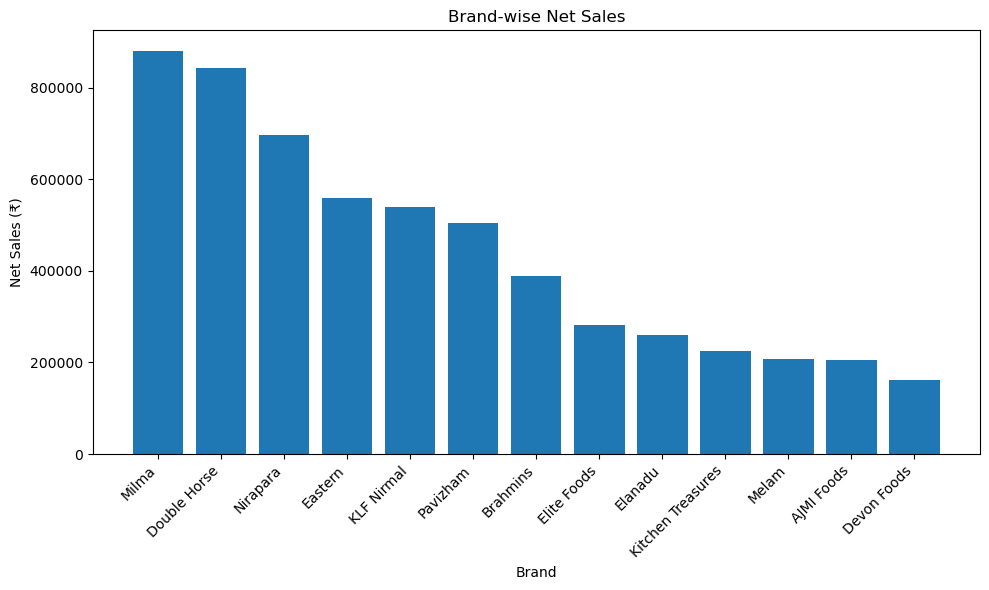

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    brand_analysis.index,
    brand_analysis["Total_Net_Sales"]
)

plt.title("Brand-wise Net Sales")
plt.xlabel("Brand")
plt.ylabel("Net Sales (₹)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "brand_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<ipython-input-94-1f84219036e6>:17: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(
<ipython-input-94-1f84219036e6>:17: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(


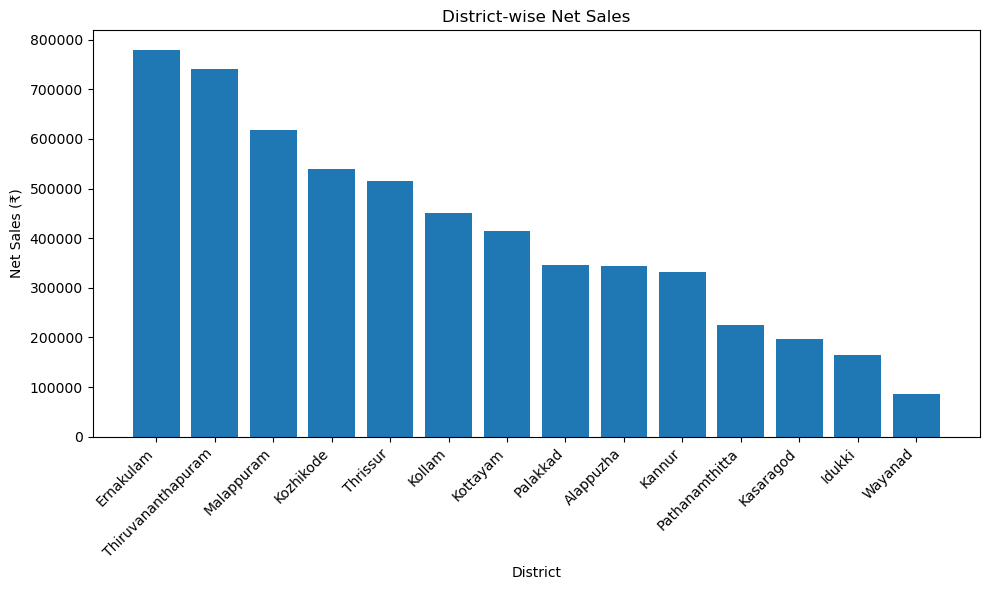

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    district_analysis.index,
    district_analysis["Total_Net_Sales"]
)

plt.title("District-wise Net Sales")
plt.xlabel("District")
plt.ylabel("Net Sales (₹)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "district_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<ipython-input-95-c2d47334a4cc>:17: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(
<ipython-input-95-c2d47334a4cc>:17: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(


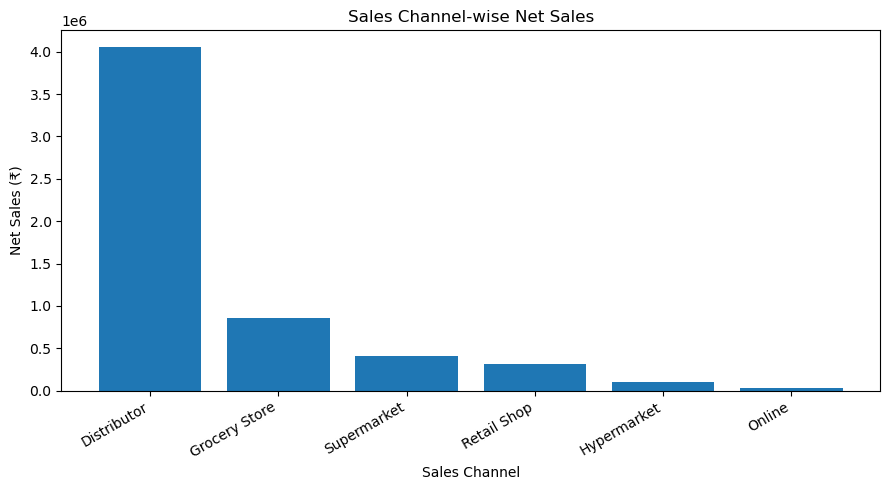

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    channel_analysis.index,
    channel_analysis["Total_Net_Sales"]
)

plt.title("Sales Channel-wise Net Sales")
plt.xlabel("Sales Channel")
plt.ylabel("Net Sales (₹)")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig(
    "channel_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<ipython-input-96-0b62a1c9b3fe>:18: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(
<ipython-input-96-0b62a1c9b3fe>:18: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(


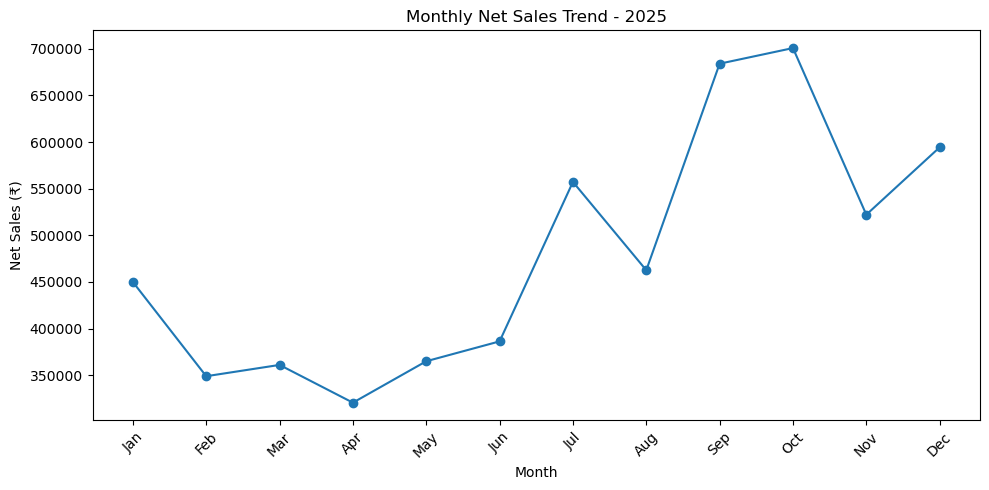

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis["Month_Name"],
    monthly_analysis["Total_Net_Sales"],
    marker="o"
)

plt.title("Monthly Net Sales Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Net Sales (₹)")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

District           Alappuzha  Ernakulam    Idukki     Kannur  Kasaragod  \
Brand                                                                     
AJMI Foods          35109.16   26380.01  18221.86    1042.14    6107.83   
Brahmins             9004.60   45917.80  19126.63   34105.78    8639.45   
Devon Foods         13312.00   14866.16   7839.45   10144.09   22662.39   
Double Horse         8835.36  111188.42  26307.25   66020.57   56877.00   
Eastern             19848.23   65593.34   7429.19  101851.04    7283.66   
Elanadu             18465.40   31275.43    836.35   30240.62   11200.40   
Elite Foods         11842.56   27463.42   1685.94    4232.62    1688.00   
KLF Nirmal          70503.02  152067.54   1577.15    4848.13    6959.33   
Kitchen Treasures   13164.21   56171.68    580.95    9224.84    2574.85   
Melam                9952.93   29505.41    393.45   16779.43    4560.49   
Milma               69191.79  101629.07  13599.31   23981.88   51594.88   
Nirapara             6474

<ipython-input-102-2976df53c680>:38: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("brand_district_heatmap.png", dpi=300, bbox_inches="tight")
<ipython-input-102-2976df53c680>:38: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("brand_district_heatmap.png", dpi=300, bbox_inches="tight")


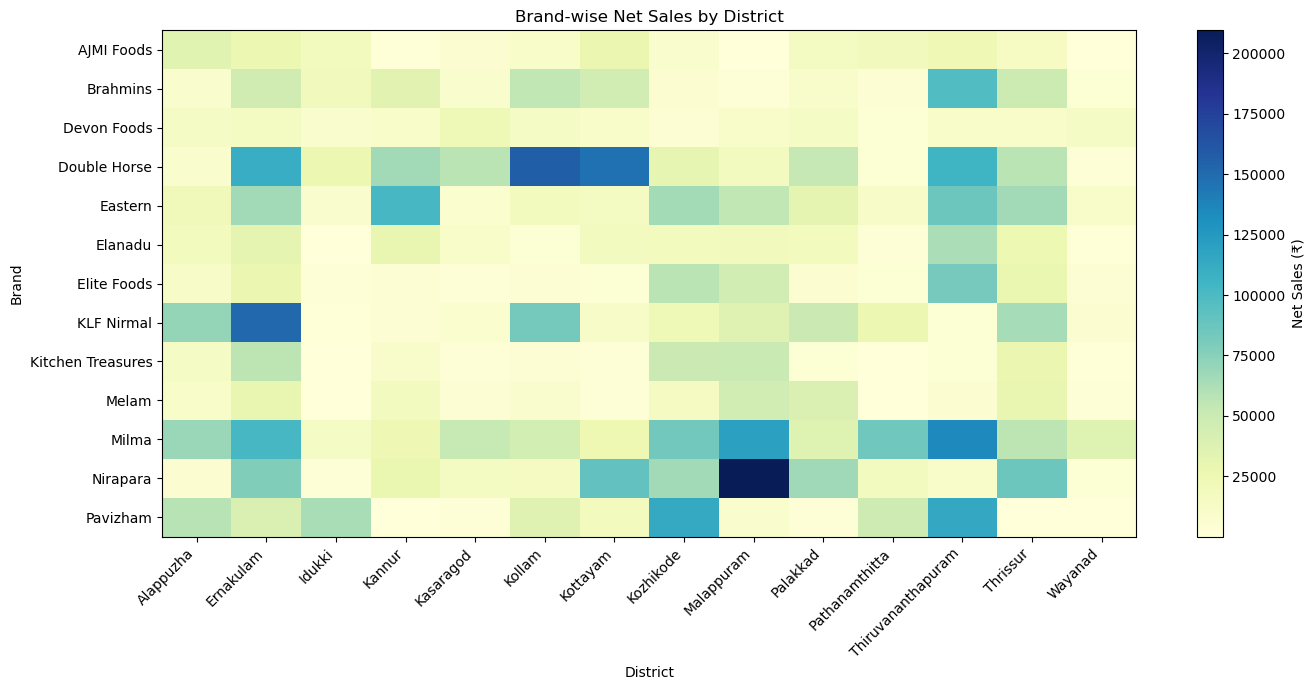

In [102]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Brand x District matrix (net sales)
brand_district = pd.pivot_table(
    df_clean,
    index="Brand",
    columns="District",
    values="Net_Sales_INR",
    aggfunc="sum",
    fill_value=0
)

print(brand_district.round(2))

# 2. Heatmap
plt.figure(figsize=(14, 7))

plt.imshow(brand_district.values, aspect="auto", cmap="YlGnBu")
plt.colorbar(label="Net Sales (₹)")

plt.xticks(
    range(len(brand_district.columns)),
    brand_district.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(brand_district.index)),
    brand_district.index
)

plt.title("Brand-wise Net Sales by District")
plt.xlabel("District")
plt.ylabel("Brand")
plt.tight_layout()

plt.savefig("brand_district_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


In [98]:
df_clean.to_csv(
    "kerala_fmcg_clean.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Rows and columns:", df_clean.shape)

Cleaned dataset exported successfully!
Rows and columns: (5000, 20)


In [99]:
check_df = pd.read_csv(
    "kerala_fmcg_clean.csv"
)

print("Dataset shape:", check_df.shape)
print("\nColumn names:")
print(check_df.columns.tolist())

print("\nFirst 5 rows:")
print(check_df.head())

Dataset shape: (5000, 20)

Column names:
['Invoice_ID', 'Date', 'Brand', 'Product', 'Category', 'District', 'Sales_Channel', 'Units_Sold', 'Unit_Price_INR', 'Gross_Sales_INR', 'Discount_Percentage', 'Discount_Amount_INR', 'Net_Sales_INR', 'Customer_Type', 'Payment_Mode', 'Year', 'Month_Num', 'Month_Name', 'Quarter', 'Weekday']

First 5 rows:
   Invoice_ID        Date              Brand                        Product  \
0  KITCH-0001  2025-01-01  Kitchen Treasures  Kitchen Treasures Curry Paste   
1   EAST-0001  2025-01-01            Eastern         Eastern Chicken Masala   
2   NIRA-0001  2025-01-01           Nirapara           Nirapara Rice Powder   
3   KLFN-0001  2025-01-01         KLF Nirmal         KLF Nirmal Coconut Oil   
4  ELITE-0001  2025-01-01        Elite Foods                     Elite Cake   

      Category    District  Sales_Channel  Units_Sold  Unit_Price_INR  \
0  Curry Paste  Malappuram    Distributor          57            90.0   
1       Masala   Kozhikode    Super

In [100]:
print("===== KERALA FMCG SALES ANALYSIS =====")

print("\n1. BRAND PERFORMANCE")
print("Highest-selling brand:", brand_analysis["Total_Net_Sales"].idxmax())
print("Highest brand net sales: ₹",
      round(brand_analysis["Total_Net_Sales"].max(), 2))
print("Lowest-selling brand:", brand_analysis["Total_Net_Sales"].idxmin())

print("\n2. DISTRICT PERFORMANCE")
print("Top district:", district_analysis["Total_Net_Sales"].idxmax())
print("Lowest district:", district_analysis["Total_Net_Sales"].idxmin())

print("\n3. MONTHLY PERFORMANCE")
print("Best month:",
      monthly_analysis.loc[
          monthly_analysis["Total_Net_Sales"].idxmax(), "Month_Name"
      ])
print("Lowest month:",
      monthly_analysis.loc[
          monthly_analysis["Total_Net_Sales"].idxmin(), "Month_Name"
      ])

print("\n4. CATEGORY PERFORMANCE")
print("Top category:", category_analysis["Total_Net_Sales"].idxmax())
print("Lowest category:", category_analysis["Total_Net_Sales"].idxmin())

print("\n5. SALES CHANNEL PERFORMANCE")
print("Top channel:", channel_analysis["Total_Net_Sales"].idxmax())
print("Lowest channel:", channel_analysis["Total_Net_Sales"].idxmin())

print("\n6. CUSTOMER TYPE")
print("Top customer type:", customer_analysis["Total_Net_Sales"].idxmax())

print("\n7. PAYMENT MODE")
print("Most-used payment mode:", payment_analysis["Invoice_Count"].idxmax())

print("\n8. OVERALL KPIs")
print("Total invoices:", df_clean["Invoice_ID"].nunique())
print("Total units sold:", df_clean["Units_Sold"].sum())
print("Total net sales: ₹", round(df_clean["Net_Sales_INR"].sum(), 2))

===== KERALA FMCG SALES ANALYSIS =====

1. BRAND PERFORMANCE
Highest-selling brand: Milma
Highest brand net sales: ₹ 881001.44
Lowest-selling brand: Devon Foods

2. DISTRICT PERFORMANCE
Top district: Ernakulam
Lowest district: Wayanad

3. MONTHLY PERFORMANCE
Best month: Oct
Lowest month: Apr

4. CATEGORY PERFORMANCE
Top category: Rice
Lowest category: Whole Spices

5. SALES CHANNEL PERFORMANCE
Top channel: Distributor
Lowest channel: Online

6. CUSTOMER TYPE
Top customer type: Distributor

7. PAYMENT MODE
Most-used payment mode: UPI

8. OVERALL KPIs
Total invoices: 5000
Total units sold: 60226
Total net sales: ₹ 5752591.73


# Key Insights: Kerala FMCG Sales 2025

**Overall:** 5,000 invoices | 60,226 units | Net sales ₹57.53 lakh | Discounts ₹6.74 lakh (10.5% of gross sales)

**1. Brands.** Milma (15.3%) and Double Horse (14.6%) together bring in about 30% of net sales. The top 5 brands add up to about 61%. Devon Foods is the smallest at 2.8%.

**2. Products and categories.** Rice is the top category at 20.9% of sales. The top 10 products make up about 43% of net sales, and Matta Rice from Double Horse and Nirapara leads. Whole Spices contribute almost nothing (0.1%).

**3. Districts.** Ernakulam (13.6%) and Thiruvananthapuram (12.9%) are the largest. Wayanad is the weakest at 1.5%, then Idukki (2.8%) and Kasaragod (3.4%). Sales are concentrated in a few districts.

**4. Seasonality.** Q4 is the strongest quarter (31.6% of sales) and Q2 the weakest. October is the best month (₹7.0 lakh) and April the worst (₹3.2 lakh), about 2.2 times lower. Is this festival season? To confirm, check weekly sales around the festival dates.

**5. Sales channels.** Distributors generate about 70% of net sales, and the average distributor invoice is about ₹5,555. Online is only 0.6% (average invoice about ₹213). This is mostly a B2B market with a very small online presence.

**6. Customers and payments.** Distributors and wholesale customers make up 84% of sales. UPI is the most-used payment mode by invoice count (44%), but bank transfers carry the largest value (42%), because of the large B2B orders.

**7. Discounts.** The weighted discount is 10.5% overall. Distributor invoices get the highest rate (11.3%) and online the lowest (6.4%). Elite Foods has the highest brand discount (11.8%) and KLF Nirmal the lowest (9.6%). Higher discount rates go with larger orders, but that doesn't prove discounts drive volume, because distributors buy in bulk and also receive the biggest discounts.

## Recommendations
- Develop online and modern-trade channels, which are very small compared with distributors.
- Build stock and promotions for the Sep–Dec peak, and investigate the April low.
- Review districts such as Wayanad, Idukki and Kasaragod for distribution gaps.
- Protect the top brands and categories (Milma, Double Horse, Rice), and check discount levels by customer type.
  